# Earth emitted and reflected light

We will now explore what the Earth looks like both in reflected and in emitted light at the same time. For this, we will use a configuation file that is loosely based on Kofman 2026.

https://arxiv.org/pdf/2604.08993

In [91]:
import os
import numpy as np
import matplotlib.pyplot as plt

In [92]:
# the configuration file will be downloaded from the github server
os.system('curl https://raw.githubusercontent.com/VincentKofman/Earth/refs/heads/main/Earth_emitted.cfg > psg_cfg_em.txt')

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 30382  100 30382    0     0   132k      0 --:--:-- --:--:-- --:--:--  133k


0

In [93]:
# Run simulation using the PSG API
os.system('curl --data-urlencode file@psg_cfg_em.txt https://psg.gsfc.nasa.gov/api.php > psg_rad_em.txt')

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 65560    0 28457  100 37103  10086  13151  0:00:02  0:00:02 --:--:-- 23231


0

In [94]:
rad = np.genfromtxt('psg_rad_em.txt')

Text(0.5, 1.0, 'Earth radiance spectrum')

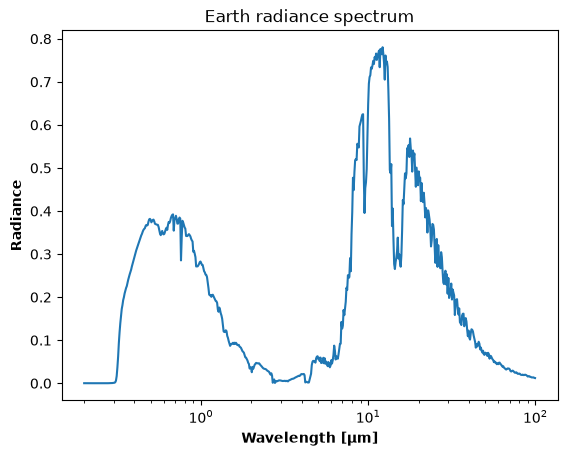

In [95]:
plt.plot(rad[:,0],rad[:,1])
plt.xscale('log')

plt.xlabel('Wavelength [µm]',    weight='bold')
plt.ylabel('Radiance',        weight='bold')
plt.title('Earth radiance spectrum')

## validate the fluxes

First things first, we have to ensure that what we're looking at is correct. Let's check the units

In [96]:
# let's integrate the infrared portion, so anything above about 2.7 µm. Find this minima between the
# reflected light and emitted light
split = np.argmin(np.abs(rad[:,0]-2.7))

In [97]:
print('Flux integrated from 2.7-100 µm:', round(np.trapezoid(rad[split:,1])*np.pi), 'W /m2')

Flux integrated from 2.7-100 µm: 253 W /m2


Considering that this is an average flux from a 1D column simulation, this is reasonable.

Following the logic in the other notebook. We can change the configuration file step-by-step to verify the reflected light flux as well.

We will have to change the following:

In [98]:
# We'll open the configuration file
fr = open('psg_cfg_em.txt')
cfg = fr.readlines()
fr.close()

cfg.append('<GENERATOR-GAS-MODEL>N\n')
cfg.append('<OBJECT-SOLAR-LONGITUDE>0')

# And save the file
fw = open('psg_cfg_test_reflected.txt','w')
fw.writelines(cfg)
fw.close()

In [99]:
# Run simulation using the PSG API
os.system('curl --data-urlencode file@psg_cfg_test_reflected.txt https://psg.gsfc.nasa.gov/api.php > psg_rad_test_refl.txt')

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 81346    0 44185  100 37161  74356  62536 --:--:-- --:--:-- --:--:--  133k


0

In [100]:
radtest = np.genfromtxt('psg_rad_test_refl.txt')

to see how much light has hit the fully illumnated disk, let's devide the integrated flux by the albedo, and by the factor (2/3) from the Lambert sphere

In [104]:
print('Flux integrated from 0.2-2.7 µm:', round(np.trapezoid(radtest[:split,1])*np.pi/0.06/(2/3)), 'W /m2')

Flux integrated from 0.2-2.7 µm: 1303 W /m2


Now that the flux in and flux out make sense, we can explore some different aspects of the Earth's radiative balance, both in reflected as well as emitted light

The full list of the configuration parameters is found here. 
https://psg.gsfc.nasa.gov/helpapi.php#parameters 



## make the figure form Kofman 2026

We will reproduce the figure from Kofman 2026 using the following code

In [108]:
labels = r'Wave/freq Total H$\bf{_2}$O CO$\bf{_2}$ O$\bf{_3}$ N$\bf{_2}$O CO CH$\bf{_4}$ O$\bf{_2}$ N$\bf{_2}$ HI Rayleigh CIA'.split() 

In [111]:
# run the transmission spectra to get the contributions from the atmosphere
# Run simulation using the PSG API
os.system('curl -d type=trn --data-urlencode file@psg_cfg_em.txt https://psg.gsfc.nasa.gov/api.php > psg_trn_em.txt')

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  142k    0  105k  100 37112  35427  12117  0:00:03  0:00:03 --:--:-- 47556


0

In [113]:
tr = np.genfromtxt('psg_trn_em.txt')

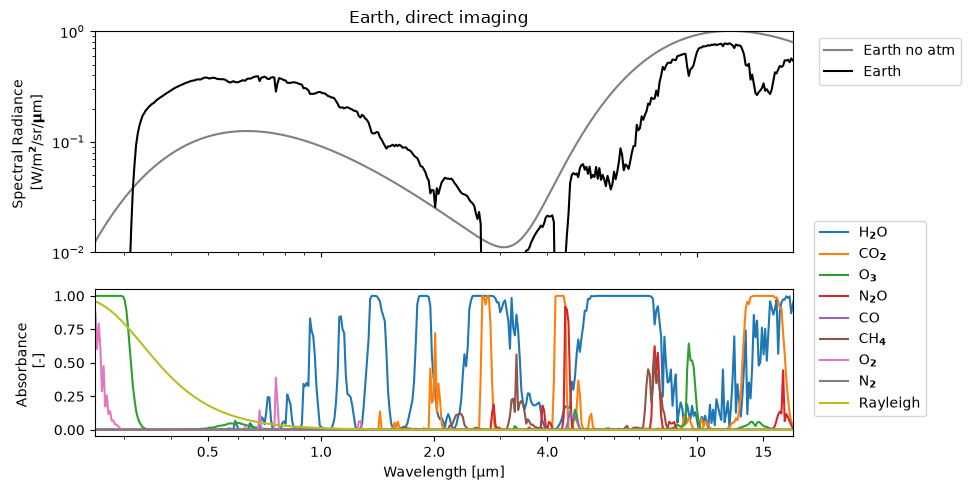

In [122]:
fig, ax =plt.subplots(figsize=(10,5),ncols=1,nrows=2, height_ratios=[1.5,1])


ax[0].plot(radtest[:,0],radtest[:,1],    c='gray',       label='Earth no atm')
# ax[0].plot(bb[:,0],ray[:,1],    c='darkblue',  label='Rayleigh')
# ax[0].plot(nc[:,0],nc[:,-1],   c='lightblue',  label='Earth no clouds')
ax[0].plot(rad[:,0],rad[:,-1], c='black',      label='Earth')
ax[0].set_yscale('log')

ax[0].set_ylim(1e-2,1)

ax[0].legend(loc='upper right',bbox_to_anchor=(1.25,1))
#ax[0,1].set_ylim(ax[0,0].get_ylim())

# ax[0].plot(HIrad[:,0],HIrad[:,-1],c='red',label='HI')
ax[0].set_ylabel('Spectral Radiance \n'+ r'[W/m$\bf{^2}$/sr/$\bf{\mu}$m]')
ax[0].set_title('Earth, direct imaging  ')



for a in range(0,8):
    #ax[1].plot(trn_10mb[:,0],1-trn_10mb[:,a+2],c= vk.cs[a],label=heads_10mb[a+2])
    ax[1].plot(tr[:,0],1-tr[:,a+2],label=labels[a+2])
a=10
ax[1].plot(tr[:,0],1-tr[:,a+2],label='Rayleigh')
    # print(np.min(trn_10mb[:,a+2]),heads_10mb[a+2])

ax[0].set_xscale('log')
ax[0].set_xlim(.25,18)
ax[1].set_xlim(.25,18)
ax[1].set_xscale('log')
#
# ax[1].legend(bbox_to_anchor=(1.05,1))
ax[1].set_xlabel(r'Wavelength [µm]')
ax[1].set_ylabel('Absorbance \n [-]')

ax[1].set_xticks([.5,1,2,4,10,15])
ax[1].set_xticklabels(['0.5','1.0','2.0','4.0','10','15'])

ax[0].set_xticklabels([])
#ax[1,1].set_yticklabels([])
#fig.hspace(.1)
fig.tight_layout()
fig.subplots_adjust(hspace = 0.2 )
#ax[2].set_ylabel('cross section \n '+r'[cm$\bf{^2}$ molecule$\bf{^-1}$]',fontproperties=bold)
ax[1].legend(bbox_to_anchor=(1.2,0.8),loc=7)
plt.savefig('demo_spectra_log.pdf',dpi=400,bbox_inches='tight')
# plt.savefig('demo404_paper_noHI.pdf',dpi=400,bbox_inches='tight')
#ax[1].set_xlim(4,5)

# Suggested follow up questions

What happens if you change the cloud fraction, both in the IR and in the reflected light?

In [ ]:
# <ATMOSPHERE-CLOUDFRACTION>0.28

Explore the difference of pressure


In [ ]:
# # <ATMOSPHERE-PRESSURE>1.0049e+00

Try changing the compositon of the atmosphere by varying the scl abundances in the line below. Note, you only need to make changes the <ATMOSPHERE-ABUN> line, the others are just included for the sake of completion. You can look up what these lines do in the repository shown at the top.

In [ ]:
# <ATMOSPHERE-NGAS>8
# <ATMOSPHERE-GAS>H2O,CO2,O3,N2O,CO,CH4,O2,N2
# <ATMOSPHERE-TYPE>HIT[1],HIT[2],HIT[3],HIT[4],HIT[5],HIT[6],HIT[7],HIT[22]
# <ATMOSPHERE-ABUN>1,1,1,1,1,1,1,1
# <ATMOSPHERE-UNIT>scl,scl,scl,scl,scl,scl,scl,scl
# <ATMOSPHERE-LAYERS-MOLECULES>H2O,CO2,O3,N2O,CO,CH4,O2,NO,SO2,NO2,NH3,HNO3,OH,HF,HCl,HBr,HI,ClO,OCS,H2CO,HOCl,N2,HCN,CH3Cl,H2O2,C2H2,C2H6,PH3,Water,WaterIce